In [24]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import seaborn as sns
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
import numpy as np

In [25]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [26]:
df["sex"] = df["sex"].str.lower()
df["sex"] = df["sex"].map({"male": 1, "female" : 0})

df["smoker"] = df["smoker"].str.lower()
df["smoker"] = df["smoker"].map({"yes":1, "no": 0})
df

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,southwest,16884.92400
1,18,1,33.770,1,0,southeast,1725.55230
2,28,1,33.000,3,0,southeast,4449.46200
3,33,1,22.705,0,0,northwest,21984.47061
4,32,1,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,northwest,10600.54830
1334,18,0,31.920,0,0,northeast,2205.98080
1335,18,0,36.850,0,0,southeast,1629.83350
1336,21,0,25.800,0,0,southwest,2007.94500


In [27]:
#Interaction Features
df["age_smoker"] = df["age"] * df["smoker"]
df["bmi_smoker"] = df["bmi"] * df["smoker"]
df["age_bmi"] = df["age"] * df["bmi"]

X = df.drop(["charges"], axis=1)
y = df["charges"]

#one hot Encoding
X = pd.get_dummies(X, columns=["region"], drop_first=True, dtype=int)

x_train, x_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2)

<Axes: >

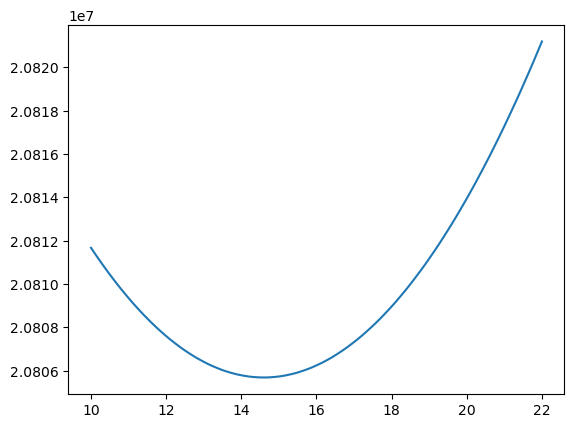

In [28]:
alphas = [10.0, 10.1, 10.2, 10.3, 10.4, 10.5, 10.6, 10.7, 10.8, 10.9, 11.0, 11.1, 11.2, 11.3, 11.4, 11.5, 11.6, 11.7, 11.8, 11.9, 12.0, 12.1, 12.2, 12.3, 12.4, 12.5, 12.6, 12.7, 12.8, 12.9, 13.0, 13.1, 13.2, 13.3, 13.4, 13.5, 13.6, 13.7, 13.8, 13.9, 14.0, 14.1, 14.2, 14.3, 14.4, 14.5, 14.6, 14.7, 14.8, 14.9, 15.0, 15.1, 15.2, 15.3, 15.4, 15.5, 15.6, 15.7, 15.8, 15.9, 16.0, 16.1, 16.2, 16.3, 16.4, 16.5, 16.6, 16.7, 16.8, 16.9, 17.0, 17.1, 17.2, 17.3, 17.4, 17.5, 17.6, 17.7, 17.8, 17.9, 18.0, 18.1, 18.2, 18.3, 18.4, 18.5, 18.6, 18.7, 18.8, 18.9, 19.0, 19.1, 19.2, 19.3, 19.4, 19.5, 19.6, 19.7, 19.8, 19.9, 20.0, 20.1, 20.2, 20.3, 20.4, 20.5, 20.6, 20.7, 20.8, 20.9, 21.0, 21.1, 21.2, 21.3, 21.4, 21.5, 21.6, 21.7, 21.8, 21.9, 22.0]
mse_a = []

for a in alphas:
    model = Lasso(alpha=a)
    model.fit(x_train, y_train)

    y_test_pred = model.predict(x_test)
    mse = mean_squared_error(y_test, y_test_pred)
    mse_a.append(mse)

sns.lineplot(x= alphas, y=mse_a)



In [29]:
best_alpha = alphas[np.argmin(mse_a)]
print("Best alpha value: ", best_alpha)

Best alpha value:  14.6


In [30]:
model = Lasso(alpha=best_alpha)
model.fit(x_train, y_train)

y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

print("Train data r2 value: ", r2_train)
print("Test data r2 value: ", r2_test)

Train data r2 value:  0.8338075930867556
Test data r2 value:  0.8659848426844823
